In [4]:
from pathlib import Path 
from io import StringIO 
import subprocess 

import pandas as pd 
import matplotlib.pyplot as plt 

PROJECT_ROOT = Path.cwd().resolve()

if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent 

FIGURES_DIR = PROJECT_ROOT / "outputs" / "figures"
FIGURES_DIR.mkdir(parents=True, exist_ok=True)

def load_sql_results(sql_file: str) -> pd.DataFrame: 
    result = subprocess.run(
        [
            "psql",
            "-X",
            "--csv",
            "-q",
            "-U", "postgres",
            "-h", "127.0.0.1",
            "-p", "5432",
            "-d", "olist_ecommerce",
            "-v", "ON_ERROR_STOP=1",
            "-f", str(PROJECT_ROOT / sql_file),
        ],
        capture_output=True,
        text=True,
        check=True,
    )

    return pd.read_csv(StringIO(result.stdout))



segments = load_sql_results(
    "sql/analysis/01_delivery_delay_vs_reviews.sql"
)

daily = load_sql_results(
    "sql/analysis/02_daily_delay_pattern.sql"
)

display(segments)
display(daily.head())

,delay_segment,reviewed_orders,avg_review_score,low_review_pct,five_star_pct
0,Early,87994,4.30,9.19,62.50
1,On time,1273,4.04,12.33,50.75
2,1-3 days late,1850,3.29,32.16,33.19
3,4-7 days late,1745,2.10,67.62,14.10
4,8-14 days late,1443,1.67,80.25,6.86
5,15+ days late,1330,1.72,78.35,7.22


,delivery_delay_days,reviewed_orders,avg_review_score,low_review_pct,five_star_pct
0,-5,2204,4.20,10.75,58.44
1,-4,1899,4.15,10.95,55.82
2,-3,1711,4.12,10.87,54.47
3,-2,1537,4.13,11.65,55.43
4,-1,1447,4.16,10.99,55.63


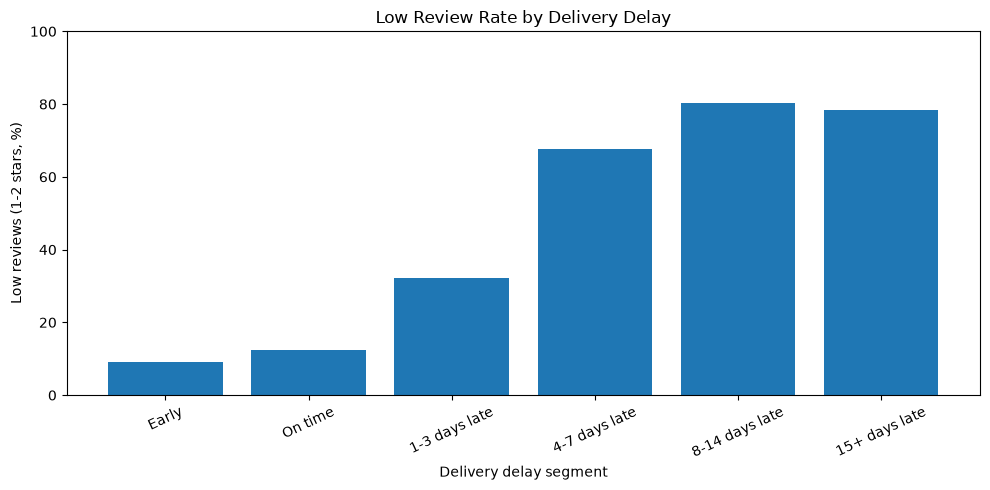

In [5]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.bar(
    segments["delay_segment"],
    segments["low_review_pct"]
)

ax.set(
    title="Low Review Rate by Delivery Delay",
    xlabel="Delivery delay segment",
    ylabel="Low reviews (1-2 stars, %)",
    ylim=(0, 100)
)

ax.tick_params(axis="x", rotation=25)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "delay_segment_low_reviews.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()

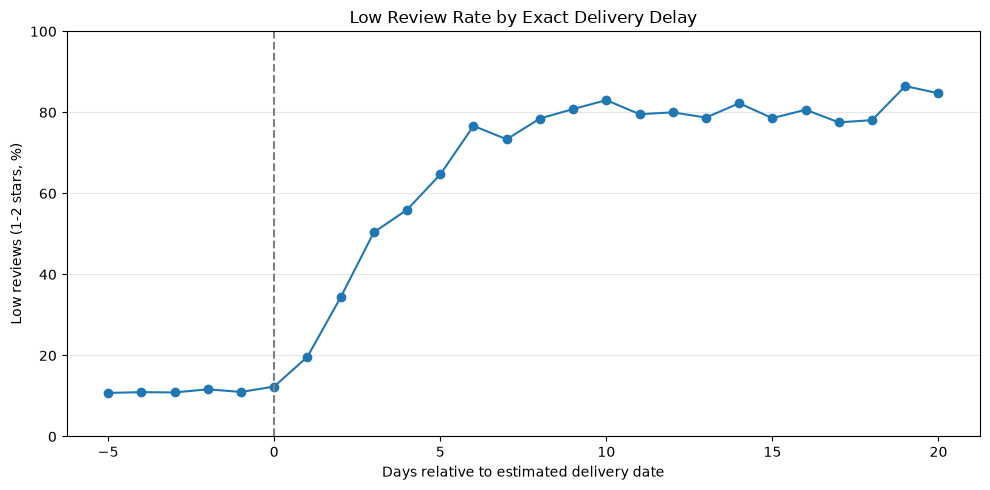

In [7]:
fig, ax = plt.subplots(figsize=(10, 5))

ax.plot(
    daily["delivery_delay_days"],
    daily["low_review_pct"],
    marker="o"
)

ax.axvline(0, linestyle="--", color="gray")

ax.set(
    title="Low Review Rate by Exact Delivery Delay",
    xlabel="Days relative to estimated delivery date",
    ylabel="Low reviews (1-2 stars, %)",
    ylim=(0, 100)
)

ax.grid(axis="y", alpha=0.3)

fig.tight_layout()

fig.savefig(
    FIGURES_DIR / "daily_delay_low_reviews.png",
    dpi=200,
    bbox_inches="tight"
)

plt.show()